# LudiStore — fidélité et prévision des ventes de jeux

**Simulation pédagogique : données synthétiques.**

Vous disposez de 180 000 lignes de vente, 9 000 clients, 1 800 articles et 36 mois d’historique. Une commande comporte plusieurs lignes ; certains documents deviennent partiels après rejet. La direction craint de confondre des effets de calendrier, des clients professionnels et des associations statistiques faibles.

## Objectif et démarche

Déterminer si la croissance provient du nombre de commandes, du panier ou de la fidélité, puis recommander une prévision comparée à une référence simple.

- Quel est le CA net par année, le nombre distinct de commandes, le panier et la part des retours ? Quels rejets rendent des commandes partielles ?
- Comment séparer tendance et saisonnalité et éviter de prendre une variation mensuelle pour une rupture structurelle ?
- Quelle rétention observe-t-on à ancienneté égale ? Comment traiter les cellules futures d’une matrice de cohortes ?
- La dépense est-elle associée à l’âge et les prix diffèrent-ils selon la catégorie ? Quelle est la taille d’effet au-delà de la p-value ?
- Un modèle ETS améliore-t-il une référence saisonnière sur les six derniers mois ? Quel biais conserve-t-il et quelle prudence faut-il garder sur ses intervalles ?

Exécuter les cellules dans l’ordre. Les sources synthétiques sont régénérées avec une graine fixe ; les données réelles éventuelles nécessiteraient une étape de chargement distincte.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


## Fonctions de qualité et de visualisation

Ces fonctions centralisent les exports CSV, la traçabilité des exclusions et les légendes des graphiques. Le bilan brut = doublons + rejets + propre est vérifié par assertion.

In [2]:
DEFAULT_UNITS = {'region': 'Région fictive', 'nom': 'Nom fictif', 'population': 'personnes', 'surface': 'm²', 'pieces': 'nombre de pièces', 'type': 'type de bien', 'date': 'ISO yyyy-MM-dd', 'prix': 'EUR/unité (transaction : EUR/bien)', 'nature': 'principal/annexe', 'categorie': 'catégorie produit', 'annee': 'année civile', 'kcal_kg': 'kcal/kg', 'production_t': 'tonnes/an', 'importations_t': 'tonnes/an', 'exportations_t': 'tonnes/an', 'variation_stock_t': 'tonnes/an, signe positif = apport au bilan', 'pertes_t': 'tonnes/an', 'alimentation_animale_t': 'tonnes/an', 'autres_usages_t': 'tonnes/an', 'cout': 'EUR/unité', 'stock_initial': 'unités, proxy de stock moyen', 'sku': 'identifiant web fictif', 'quantite': 'unités', 'remise': 'fraction, 0.10 = 10 %', 'retour': 'unités retournées', 'age': 'années', 'anciennete': 'années', 'segment': 'particulier/professionnel fictif', 'sexe': 'F/H, catégories simplifiées de la simulation', 'niveau': 'niveau de poste fictif', 'metier': 'famille métier fictive', 'site': 'site fictif', 'quotite': 'ETP contractuel, 0 < x <= 1', 'salaire_annuel_verse': 'EUR/an au temps contractuel', 'pays': 'territoire fictif', 'zone': 'Rural/Urbain', 'acces_sur_pct': 'pourcentage 0–100', 'budget_millions_eur': 'millions EUR', 'cout_beneficiaire_eur': 'EUR/personne', 'pib_habitant': 'USD fictifs/personne/an', 'conso_kg_hab': 'kg/personne/an', 'risque_logistique': 'score 0–100, élevé défavorable', 'croissance_pct': 'points de pourcentage annuel', 'est_faux': '1=faux simulé, 0=authentique simulé', 'diagonale': 'mm', 'hauteur_gauche': 'mm', 'hauteur_droite': 'mm', 'marge_haute': 'mm', 'marge_basse': 'mm', 'longueur': 'mm'}

def csv(df, file):
    df.to_csv(file, index=False, sep=';', encoding='utf-8-sig', float_format='%.8f')

def source(df, name, grain, units=None):
    csv(df, RAW / (name + '.csv'))
    for c in df:
        DICT.append({'table': name, 'grain': grain, 'colonne': c, 'type': str(df[c].dtype), 'unite_ou_sens': (units or {}).get(c, DEFAULT_UNITS.get(c, 'Identifiant fictif' if c.endswith('_id') else 'Voir énoncé et code de génération')), 'manquants': int(df[c].isna().sum())})

def clean(df, key, mask, name):
    dup = df.duplicated(key, keep='first')
    u = df.loc[~dup].copy()
    valid = mask(u).fillna(False)
    rejects = u.loc[~valid].copy()
    rejects['motif'] = 'Contrat de validation violé : voir les cellules de nettoyage du notebook'
    csv(df.loc[dup], OUT / (name + '_doublons.csv'))
    csv(rejects, OUT / (name + '_rejets.csv'))
    r = u.loc[valid].copy()
    AUDIT.append({'table': name, 'brut': len(df), 'doublons': int(dup.sum()), 'rejets': len(rejects), 'propre': len(r)})
    csv(r, CLEAN / (name + '.csv'))
    assert len(df) == int(dup.sum()) + len(rejects) + len(r)
    assert not r.duplicated(key).any()
    return r

FIGURE_LABELS = {'flux_stations': ('Solde des flux par station', 'Identifiant de station', 'Arrivées moins départs, locations'), 'ca_maintenance': ('Recettes et maintenance mensuelles', 'Mois', 'EUR'), 'prix_m2_annuel': ('Prix au m² — territoires fictifs', 'Année', 'Médiane des médianes communales, EUR/m²'), 'erreurs_prediction': ('Erreurs du modèle sur 2025', 'Prédiction moins prix réel, EUR', 'Nombre de ventes'), 'disponibilite_ponderee': ('Disponibilité calorique — bilans complets', 'Année', 'kcal/jour/personne, pondéré par population'), 'dependance_et_disponibilite': ('Dépendance aux importations et disponibilité', 'Importations / (production + importations)', 'Disponibilité, kcal/jour/personne'), 'distribution_prix': ('Distribution des prix catalogue', 'Logarithme naturel du prix en EUR', 'Nombre de références'), 'pareto_ca': ('Concentration du chiffre d’affaires', 'Fraction des références, par CA décroissant', 'Fraction cumulée du CA'), 'ca_et_marge_mensuels': ('Ventes et marge commerciale', 'Mois', 'EUR'), 'decomposition': ('Série mensuelle et décomposition STL', 'Mois', 'EUR'), 'validation_prevision': ('Prévision — six mois de test chronologique', 'Mois', 'Chiffre d’affaires net, EUR'), 'retention_cohortes': ('Rétention par cohorte — cellules futures non observées', 'Ancienneté en mois', 'Cohorte, ordre chronologique'), 'salaires_etp': ('Distribution des salaires normalisés ETP', 'Catégorie de sexe simulée', 'EUR/an équivalent temps plein'), 'ecarts_brut_ajuste': ('Écart salarial descriptif', 'Méthode', 'Écart en %, référence masculine'), 'besoin_regional': ('Population sans accès — données observées', 'Année', '% de la population observée'), 'stabilite_priorites': ('Sensibilité des priorités à la pondération', 'Identifiant du territoire fictif', 'Rang (1 = priorité maximale)'), 'acp_clusters': ('Segmentation des marchés fictifs — projection ACP', 'Composante principale 1, score standardisé', 'Composante principale 2, score standardisé'), 'choix_k': ('Sélection du nombre de clusters', 'Nombre de clusters k', 'Score silhouette'), 'stabilite': ('Stabilité du clustering, 30 sous-échantillons', 'ARI versus partition de référence', 'Nombre de réplications'), 'courbe_roc': ('Courbe ROC — défaut = classe positive', 'Taux de faux positifs', 'Taux de vrais positifs'), 'choix_seuil_validation': ('Sélection du seuil, données de validation', 'Seuil de probabilité', 'Coût conventionnel = 20 × FN + FP'), 'matrice_confusion': ('Matrice de confusion — jeu test', 'Classe prédite', 'Classe réelle')}

def figure(name, draw):
    fig, ax = plt.subplots()
    draw(ax)
    title, xlabel, ylabel = FIGURE_LABELS.get(name, (name.replace('_', ' ').capitalize(), '', ''))
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    handles, legend = ax.get_legend_handles_labels()
    if handles:
        mapping = {'reel': 'Observé', 'ets': 'Prévision ETS', 'naif_saisonnier': 'Référence saisonnière', 'ca': 'CA net', 'marge': 'Marge commerciale', 'ca_net': 'CA net', 'tendance': 'Tendance STL', 'saisonnalite': 'Saisonnalité STL', 'rang_min': 'Rang minimal', 'rang_max': 'Rang maximal', 'kcal_ponderees': 'Disponibilité pondérée'}
        ax.legend(handles, [mapping.get(v, v) for v in legend], fontsize=9)
    if name in ['retention_cohortes', 'matrice_confusion'] and ax.images:
        fig.colorbar(ax.images[0], ax=ax, label='Taux de rétention' if name == 'retention_cohortes' else 'Nombre de pièces')
    if name == 'matrice_confusion':
        ax.set_xticks([0, 1], ['Conforme', 'Défaut'])
        ax.set_yticks([0, 1], ['Conforme', 'Défaut'])
        a = ax.images[0].get_array()
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(int(a[i, j])), ha='center', va='center', color='white' if a[i, j] > a.max() / 2 else 'black', fontsize=16)
    if name == 'acp_clusters' and ax.collections:
        fig.colorbar(ax.collections[0], ax=ax, label='Identifiant de cluster')
    fig.tight_layout()
    fig.savefig(REPORT / (name + '.png'), dpi=140)
    FIGS.append((name, fig))

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


## Étape 1 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [3]:
import os

## Étape 2 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [4]:
os.environ.setdefault('OMP_NUM_THREADS', '2')

'2'

## Étape 3 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [5]:
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')

'2'

## Étape 4 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [6]:
from statsmodels.tsa.seasonal import STL

## Étape 5 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [7]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

## Étape 6 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [8]:
from sklearn.metrics import mean_absolute_error

## Étape 7 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [9]:
n = 180000

## Étape 8 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [10]:
clients = pd.DataFrame({'client_id': np.arange(9000), 'age': RNG.integers(18, 86, 9000), 'segment': RNG.choice(['Particulier', 'Professionnel'], 9000, p=[0.96, 0.04])})

## Étape 9 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [11]:
books = pd.DataFrame({'article_id': np.arange(1800), 'categorie': RNG.choice(['Jeux_societe', 'Puzzles', 'Jeux_educatifs'], 1800), 'prix': RNG.lognormal(3.3, 0.45, 1800).round(2)})

## Étape 10 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [12]:
months = np.arange(36)
weights = 1 + 0.25 * np.sin(2 * np.pi * (months - 8) / 12) + months * 0.008
mi = RNG.choice(months, n // 2, p=weights / weights.sum())
starts = pd.date_range('2023-01-01', periods=36, freq='MS')
dates = starts[mi] + pd.to_timedelta(RNG.integers(0, 28, n // 2), unit='D')

## Étape 11 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [13]:
v = pd.DataFrame({'ligne_id': np.arange(n), 'commande_id': np.arange(n) // 2, 'client_id': np.repeat(RNG.integers(0, 9000, n // 2), 2), 'article_id': RNG.integers(0, 1800, n), 'date': np.repeat(dates.strftime('%Y-%m-%d'), 2), 'quantite': RNG.integers(1, 4, n), 'retour': RNG.binomial(1, 0.025, n)})

## Étape 12 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [14]:
v.loc[:39, 'article_id'] = 99999
v.loc[40:69, 'date'] = 'date_inconnue'
v = pd.concat([v, v.iloc[500:650]], ignore_index=True)

## Étape 13 — Documenter les données simulées

Les tables sources sont enregistrées en CSV avec leur grain, leurs unités et les valeurs manquantes. La graine fixe rend la simulation reproductible.

In [15]:
source(clients, 'clients', 'client')
source(books, 'articles', 'article')
source(v, 'transactions', 'ligne commande')

## Étape 14 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [16]:
v = clean(v, 'ligne_id', lambda x: x.article_id.isin(books.article_id) & x.client_id.isin(clients.client_id) & pd.to_datetime(x.date, errors='coerce').notna(), 'ventes')
v = v.merge(books, on='article_id', validate='many_to_one').merge(clients, on='client_id', validate='many_to_one')
v['ca_net'] = np.round((v.quantite - v.retour) * v.prix, 2)
v['date'] = pd.to_datetime(v.date)
v['mois'] = v.date.dt.to_period('M').astype(str)

## Étape 15 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [17]:
orders = v.groupby('commande_id').agg(client_id=('client_id', 'first'), date=('date', 'first'), ca_net=('ca_net', 'sum')).reset_index()
orders['mois'] = orders.date.dt.to_period('M')
monthly = v.groupby('mois').ca_net.sum().reindex(pd.period_range('2023-01', '2025-12', freq='M').astype(str), fill_value=0)

## Étape 16 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [18]:
train, test = (monthly.iloc[:-6], monthly.iloc[-6:])
ets = ExponentialSmoothing(train.to_numpy(), trend='add', seasonal='add', seasonal_periods=12).fit()
pred = ets.forecast(6)
baseline = monthly.iloc[-18:-12].to_numpy()
forecast = pd.DataFrame({'mois': test.index, 'reel': test.values, 'ets': pred, 'naif_saisonnier': baseline})
resid = np.asarray(ets.resid)
draws = pred[None, :] + RNG.choice(resid, (1500, 6), replace=True)
forecast['q05_bootstrap'] = np.quantile(draws, 0.05, axis=0)
forecast['q95_bootstrap'] = np.quantile(draws, 0.95, axis=0)

## Étape 17 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [19]:
stl = STL(monthly.to_numpy(), period=12, robust=True).fit()
decomp = pd.DataFrame({'mois': monthly.index, 'ca_net': monthly.values, 'tendance': stl.trend, 'saisonnalite': stl.seasonal})
rfm = orders.groupby('client_id').agg(derniere=('date', 'max'), frequence=('commande_id', 'nunique'), montant=('ca_net', 'sum')).reset_index()
rfm['recence'] = (orders.date.max() - rfm.derniere).dt.days
rfm = rfm.merge(clients, on='client_id', validate='one_to_one')
rho, p = stats.spearmanr(rfm.age, rfm.montant)

## Étape 18 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [20]:
groups = [g.prix.to_numpy() for _, g in books.groupby('categorie')]
kw = stats.kruskal(*groups)
epsilon = max(0, (kw.statistic - len(groups) + 1) / (len(books) - len(groups)))

## Étape 19 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [21]:
orders['cohorte'] = orders.groupby('client_id').mois.transform('min')
orders['age_cohorte'] = [m.ordinal - c.ordinal for m, c in zip(orders.mois, orders.cohorte)]
coh = orders.groupby(['cohorte', 'age_cohorte']).client_id.nunique().unstack().reindex(columns=range(36))

## Étape 20 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [22]:
for cohort in coh.index:
    observed_months = pd.Period('2025-12', 'M').ordinal - cohort.ordinal + 1
    coh.loc[cohort, list(range(observed_months))] = coh.loc[cohort, list(range(observed_months))].fillna(0)

## Étape 21 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [23]:
ret = coh.div(coh[0], axis=0)
ret.columns = ['M' + str(i) for i in ret.columns]
ret = ret.reset_index()
ret.cohorte = ret.cohorte.astype(str)

## Étape 22 — Visualiser les résultats

Les graphiques décrivent les variables et les comparaisons calculées dans les cellules précédentes. Les axes et leurs unités sont explicités.

In [24]:
figure('decomposition', lambda ax: decomp.plot(x='mois', y=['ca_net', 'tendance', 'saisonnalite'], ax=ax, rot=65))
figure('validation_prevision', lambda ax: forecast.plot(x='mois', y=['reel', 'ets', 'naif_saisonnier'], ax=ax, marker='o'))
figure('retention_cohortes', lambda ax: ax.imshow(ret.drop(columns='cohorte').iloc[:24, :18], aspect='auto', vmin=0, vmax=1, cmap='Greens'))

## Étape 23 — Restituer les résultats

Les indicateurs et les tableaux sont exportés en CSV ; les conclusions et les limites sont conservées pour la présentation.

## Résultats recalculés

         indicateur        valeur
0      transactions  1.799300e+05
1         commandes  8.996500e+04
2            ca_net  1.067189e+07
3   spearman_age_ca  6.440237e-03
4        spearman_p  5.412684e-01
5    kruskal_prix_p  2.655947e-01
6     epsilon_carre  3.625863e-04
7           mae_ets  5.584298e+03
8          mae_naif  2.454484e+04
9        train_mois  3.000000e+01
10        test_mois  6.000000e+00

- 179,930 lignes rapprochées ; statistiques clients calculées au grain client.

- Spearman âge/dépense : 0.006 ; taille d’effet Kruskal : 0.0004.

- MAE ETS six mois : 5,584 EUR ; baseline : 24,545 EUR.

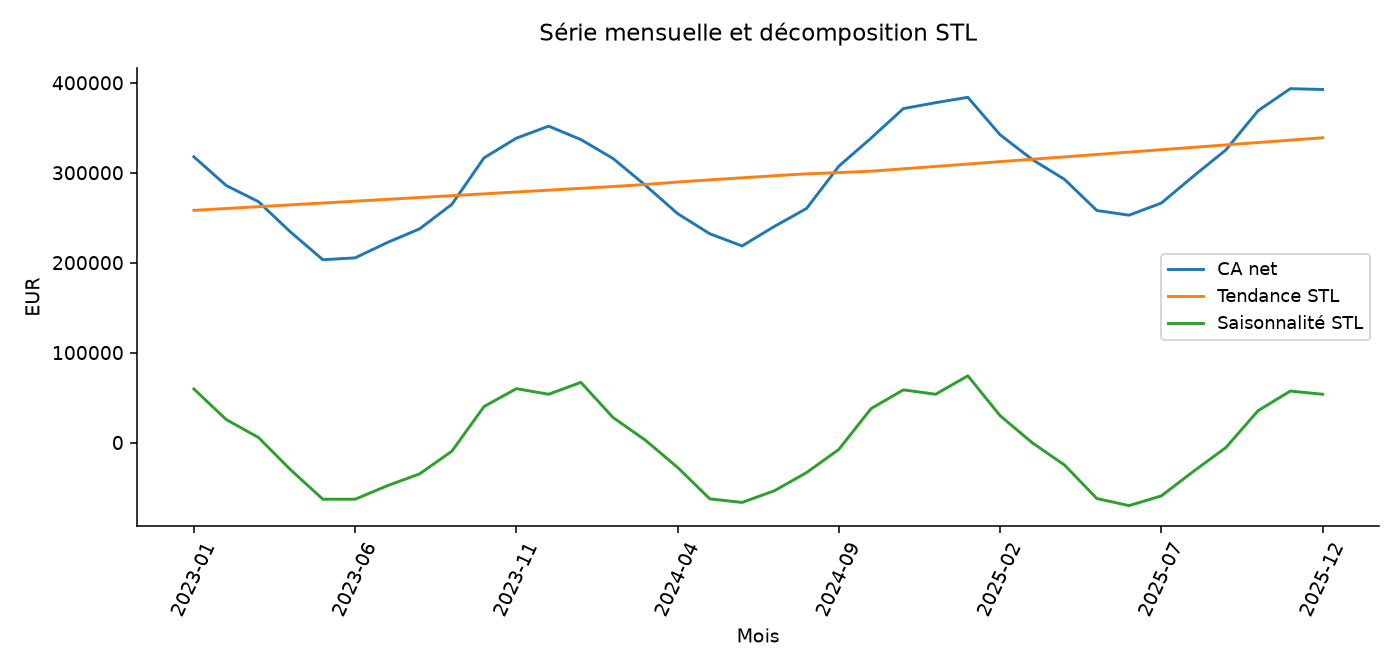

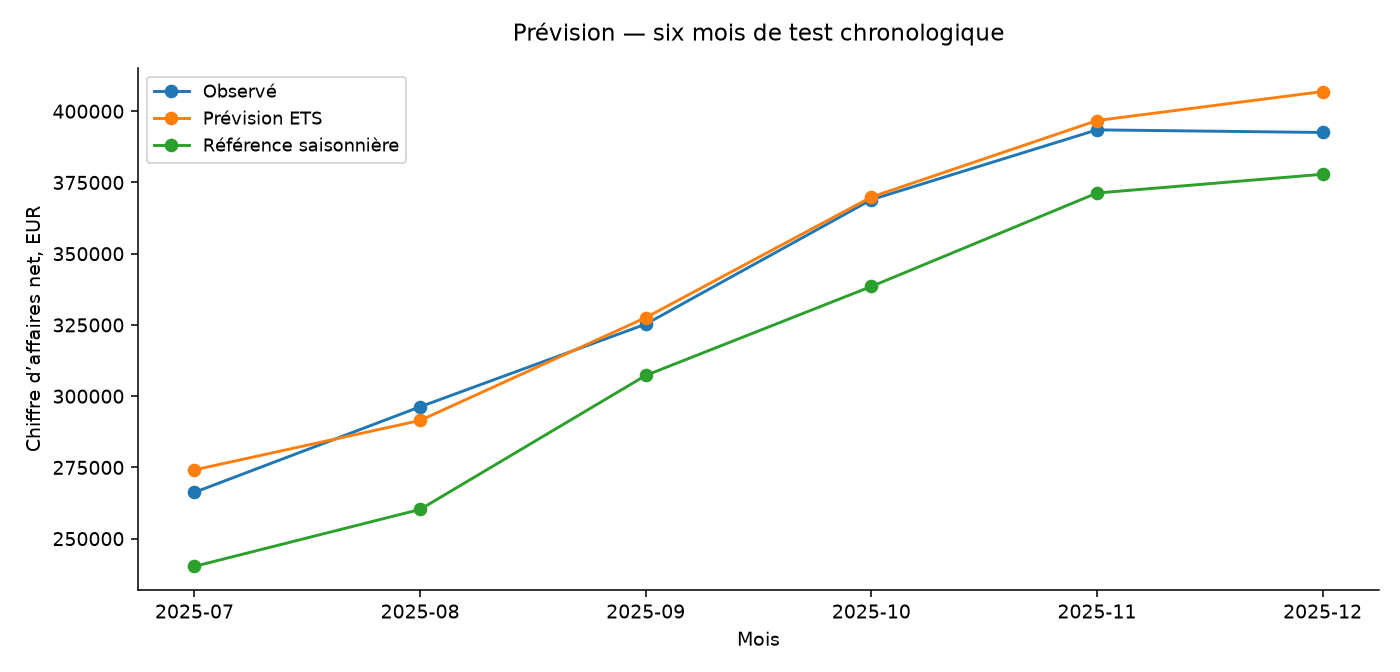

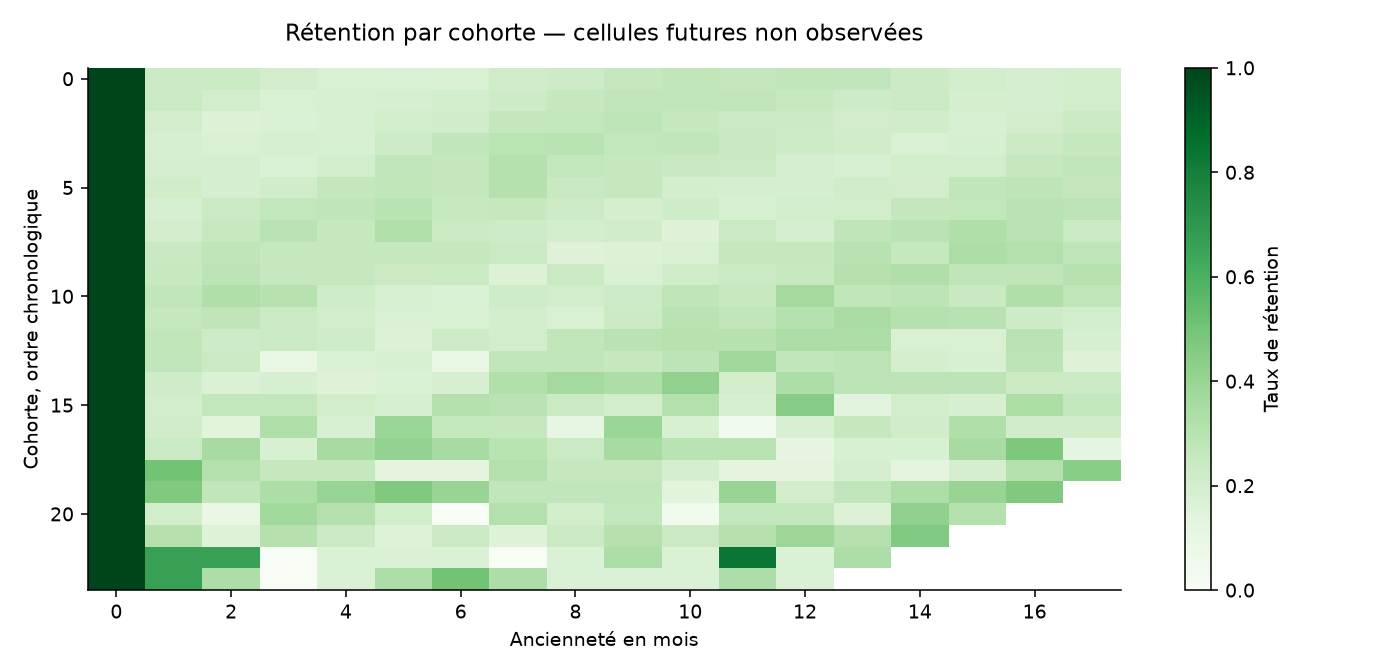

In [25]:
finish('LudiStore — fidélité et saisonnalité', 'Séparer croissance, saisonnalité et fidélité ; tester une prévision hors période.', {'transactions': len(v), 'commandes': len(orders), 'ca_net': v.ca_net.sum(), 'spearman_age_ca': rho, 'spearman_p': p, 'kruskal_prix_p': kw.pvalue, 'epsilon_carre': epsilon, 'mae_ets': mean_absolute_error(test, pred), 'mae_naif': mean_absolute_error(test, baseline), 'train_mois': 30, 'test_mois': 6}, {'cohortes_retention': ret, 'rfm_clients': rfm, 'decomposition': decomp, 'validation_prevision': forecast}, [f'{len(v):,} lignes rapprochées ; statistiques clients calculées au grain client.', f'Spearman âge/dépense : {rho:.3f} ; taille d’effet Kruskal : {epsilon:.4f}.', f'MAE ETS six mois : {mean_absolute_error(test, pred):,.0f} EUR ; baseline : {mean_absolute_error(test, baseline):,.0f} EUR.'], ['Retenir une prévision seulement si elle améliore la référence saisonnière.', 'Comparer les cohortes à ancienneté égale.'], ['Tests descriptifs sur simulation, aucune causalité réelle.', 'Bootstrap des résidus indicatif, sans garantie de couverture avec autocorrélation.', 'Cellules des cohortes non observées vides ; elles ne valent pas zéro.'])

In [26]:
import pandas as pd, numpy as np

## Analyse approfondie et interprétation

Les calculs suivants relisent les CSV produits par ce notebook et les confrontent aux hypothèses métier. Les tableaux affichés sont limités à trente lignes ; les exports CSV restent complets.

In [27]:
r = Restitution()

In [28]:
m = r.m

In [29]:
n = r.number

In [30]:
p = r.pct

In [31]:
e = r.money

In [32]:
v = r.read('data/processed/ventes.csv')

In [33]:
articles = r.read('data/raw/articles.csv')

In [34]:
clients = r.read('data/raw/clients.csv')

In [35]:
v = v.merge(articles, on='article_id', validate='many_to_one').merge(clients, on='client_id', validate='many_to_one')

In [36]:
v['ca_net'] = np.round((v.quantite - v.retour) * v.prix, 2)

In [37]:
v['annee'] = v.date.str[:4]

In [38]:
annual = v.groupby('annee').agg(ca_net=('ca_net', 'sum'), commandes=('commande_id', 'nunique'), clients=('client_id', 'nunique'), unites=('quantite', 'sum'), retours=('retour', 'sum')).reset_index()

In [39]:
annual['panier'] = annual.ca_net / annual.commandes

In [40]:
annual['taux_retour_unites'] = annual.retours / annual.unites

In [41]:
segments = v.groupby('segment').agg(ca_net=('ca_net', 'sum'), clients=('client_id', 'nunique'), commandes=('commande_id', 'nunique')).reset_index()

In [42]:
segments['ca_par_client'] = segments.ca_net / segments.clients

In [43]:
segments['part_ca'] = segments.ca_net / segments.ca_net.sum()

In [44]:
forecast = r.read('analysis/validation_prevision.csv')

In [45]:
co = r.read('analysis/cohortes_retention.csv')

In [46]:
rfm = r.read('analysis/rfm_clients.csv')

In [47]:
v['date'] = pd.to_datetime(v.date)

In [48]:
v['mois'] = v.date.dt.to_period('M')

In [49]:
first = v.groupby('client_id').mois.min()

In [50]:
cohort_size = first.value_counts().rename_axis('cohorte').rename('effectif_initial').reset_index()

In [51]:
cohort_size.cohorte = cohort_size.cohorte.astype(str)

In [52]:
co = co.merge(cohort_size, on='cohorte', validate='one_to_one')

In [53]:
ret = []

In [54]:
for age in [1, 3, 6, 12, 24]:
    observed = co['M' + str(age)].notna()
    ret.append({'anciennete_mois': age, 'cohortes_observables': int(observed.sum()), 'clients_initialement_exposes': co.loc[observed, 'effectif_initial'].sum(), 'retention_ponderee': np.average(co.loc[observed, 'M' + str(age)], weights=co.loc[observed, 'effectif_initial'])})

In [55]:
ret = pd.DataFrame(ret)

In [56]:
orders = v.groupby('commande_id').agg(lignes=('ligne_id', 'size'), ca=('ca_net', 'sum'))

In [57]:
partial = int(orders.lignes.lt(2).sum())

In [58]:
improvement = 1 - m['mae_ets'] / m['mae_naif']

In [59]:
bias = (forecast.ets - forecast.reel).mean()

In [60]:
coverage = ((forecast.reel >= forecast.q05_bootstrap) & (forecast.reel <= forecast.q95_bootstrap)).mean()

In [61]:
rf = rfm.sort_values('montant', ascending=False)

In [62]:
share20 = rf.head(int(np.ceil(len(rf) * 0.2))).montant.sum() / rf.montant.sum()

In [63]:
prices = articles.groupby('categorie').prix.agg(['count', 'mean', 'median', 'std']).reset_index()

In [64]:
r.resume = [f"LudiStore conserve {n(m['transactions'], 0)} lignes, {n(m['commandes'], 0)} commandes et {e(m['ca_net'])} de recettes nettes simulées. {partial} commandes conservées ne disposent plus que d’une ligne valide après contrôle.", f"L’ETS obtient une MAE de {e(m['mae_ets'])} sur six mois, contre {e(m['mae_naif'])} pour la référence saisonnière, soit {p(improvement, 1)} de réduction sur ce seul test.", f"L’association âge/dépense est très faible : Spearman {n(m['spearman_age_ca'], 4)}, p-value {n(m['spearman_p'], 4)}. Le résultat ne justifie pas un ciblage commercial par âge.", f'Les 20 % de clients les plus dépensiers représentent {p(share20, 1)} des recettes. Les cohortes doivent être comparées à ancienneté égale et pondérées par leur taille.']

In [65]:
r.section('4. Définir les unités d’analyse et les commandes partielles', ['La table brute contient des lignes de commande, pas des commandes indépendantes. Une commande possède plusieurs articles, un client et une date. Les indicateurs de panier sont calculés après regroupement par commande ; les indicateurs de comportement sont calculés après regroupement par client.', f'Le nettoyage conserve {n(len(v), 0)} lignes. {partial} commandes conservées ont moins de deux lignes valides, alors que le générateur en créait deux. Leur montant et leur panier peuvent donc être partiels ; cette limite doit accompagner toute comparaison de ticket moyen.', 'Le CA net de ligne est (quantité − quantité retournée) × prix, arrondi au centime. Le taux de retour en unités est somme des retours / somme des quantités, et non le pourcentage de lignes contenant un retour. Le nombre de clients distincts n’est pas additif entre années.', 'Le référentiel client contient un segment professionnel/particulier fictif. Les achats professionnels pourraient peser davantage par client ; le tableau ci-dessous le vérifie plutôt que de l’affirmer. Aucun volume d’achat minimum réel ou effet de contrat n’est modélisé.'], [('Bilan annuel', annual), ('Profils clients', segments)])

## 4. Définir les unités d’analyse et les commandes partielles

La table brute contient des lignes de commande, pas des commandes indépendantes. Une commande possède plusieurs articles, un client et une date. Les indicateurs de panier sont calculés après regroupement par commande ; les indicateurs de comportement sont calculés après regroupement par client.

Le nettoyage conserve 179 930 lignes. 0 commandes conservées ont moins de deux lignes valides, alors que le générateur en créait deux. Leur montant et leur panier peuvent donc être partiels ; cette limite doit accompagner toute comparaison de ticket moyen.

Le CA net de ligne est (quantité − quantité retournée) × prix, arrondi au centime. Le taux de retour en unités est somme des retours / somme des quantités, et non le pourcentage de lignes contenant un retour. Le nombre de clients distincts n’est pas additif entre années.

Le référentiel client contient un segment professionnel/particulier fictif. Les achats professionnels pourraient peser davantage par client ; le tableau ci-dessous le vérifie plutôt que de l’affirmer. Aucun volume d’achat minimum réel ou effet de contrat n’est modélisé.

### Bilan annuel

  annee      ca_net  commandes  clients  unites  retours      panier  \
0  2023  3245649.85      27334     8594  109496     1363  118.740391   
1  2024  3539453.08      29873     8666  119261     1512  118.483349   
2  2025  3886782.28      32758     8749  131087     1592  118.651391   

   taux_retour_unites  
0            0.012448  
1            0.012678  
2            0.012145  

### Profils clients

         segment       ca_net  clients  commandes  ca_par_client   part_ca
0    Particulier  10256564.75     8643      86446    1186.690356  0.961083
1  Professionnel    415320.46      357       3519    1163.362633  0.038917

In [66]:
r.section('5. Distinguer tendance, saisonnalité et contribution du panier', ['Les 36 mois couvrent trois années complètes. Le générateur programme une saisonnalité des volumes et une progression graduelle. La décomposition STL sépare une tendance lissée, un effet saisonnier et un résidu sur la série complète ; c’est une analyse descriptive, pas un modèle entraîné pour prévoir le futur.', f"Le CA total de {e(m['ca_net'])} doit être lu avec le volume de commandes et le panier. Un changement de recettes ne démontre pas une hausse de fidélité ou un effet marketing. Les agrégats annuels permettent de voir quels composants bougent avant de proposer une explication.", 'Une comparaison de deux mois consécutifs peut confondre calendrier et tendance. Le choix de fenêtres annuelles complètes et d’une référence saisonnière réduit ce risque. Les variations simulées ne peuvent cependant pas être attribuées à une cause commerciale absente des données.', 'La prévision n’utilise pas la décomposition complète pour construire ses paramètres : elle est ajustée uniquement sur les trente premiers mois. Cette séparation évite d’utiliser implicitement les six mois test dans l’apprentissage.'])

## 5. Distinguer tendance, saisonnalité et contribution du panier

Les 36 mois couvrent trois années complètes. Le générateur programme une saisonnalité des volumes et une progression graduelle. La décomposition STL sépare une tendance lissée, un effet saisonnier et un résidu sur la série complète ; c’est une analyse descriptive, pas un modèle entraîné pour prévoir le futur.

Le CA total de 10 671 885 EUR doit être lu avec le volume de commandes et le panier. Un changement de recettes ne démontre pas une hausse de fidélité ou un effet marketing. Les agrégats annuels permettent de voir quels composants bougent avant de proposer une explication.

Une comparaison de deux mois consécutifs peut confondre calendrier et tendance. Le choix de fenêtres annuelles complètes et d’une référence saisonnière réduit ce risque. Les variations simulées ne peuvent cependant pas être attribuées à une cause commerciale absente des données.

La prévision n’utilise pas la décomposition complète pour construire ses paramètres : elle est ajustée uniquement sur les trente premiers mois. Cette séparation évite d’utiliser implicitement les six mois test dans l’apprentissage.

In [67]:
r.section('6. Lire les cohortes et la concentration clients', ['Une cohorte regroupe les clients selon leur premier mois observé. La rétention au mois Mx est le nombre de clients actifs à cette ancienneté divisé par le nombre initial de clients de la cohorte. Un client peut être retenu à M3 sans l’être à M2 ; cette mesure décrit une activité mensuelle, pas une survie continue.', 'Les cellules futures restent non observées. Les mois déjà écoulés sans achat valent zéro. Remplacer les cellules futures par zéro dégraderait artificiellement les cohortes récentes. La moyenne publiée est pondérée par les effectifs initiaux des seules cohortes observables à l’ancienneté considérée.', f'La concentration observée est de {p(share20, 1)} des recettes pour les 20 % de clients les plus dépensiers. Il s’agit d’un classement rétrospectif ; utiliser tout l’historique pour cibler une campagne dans le passé créerait une fuite temporelle.', 'Les variables RFM sont récence depuis la dernière date du jeu, fréquence de commandes distinctes et montant cumulé. Elles ne sont pas un score de valeur future. Un test de fidélisation devrait définir une date de coupe et mesurer les achats après cette date, avec un groupe de comparaison.'], [('Rétention à ancienneté comparable', ret), ('Effectifs des premières cohortes', co[['cohorte', 'effectif_initial', 'M1', 'M3', 'M6', 'M12']].head(12))])

## 6. Lire les cohortes et la concentration clients

Une cohorte regroupe les clients selon leur premier mois observé. La rétention au mois Mx est le nombre de clients actifs à cette ancienneté divisé par le nombre initial de clients de la cohorte. Un client peut être retenu à M3 sans l’être à M2 ; cette mesure décrit une activité mensuelle, pas une survie continue.

Les cellules futures restent non observées. Les mois déjà écoulés sans achat valent zéro. Remplacer les cellules futures par zéro dégraderait artificiellement les cohortes récentes. La moyenne publiée est pondérée par les effectifs initiaux des seules cohortes observables à l’ancienneté considérée.

La concentration observée est de 30,3 % des recettes pour les 20 % de clients les plus dépensiers. Il s’agit d’un classement rétrospectif ; utiliser tout l’historique pour cibler une campagne dans le passé créerait une fuite temporelle.

Les variables RFM sont récence depuis la dernière date du jeu, fréquence de commandes distinctes et montant cumulé. Elles ne sont pas un score de valeur future. Un test de fidélisation devrait définir une date de coupe et mesurer les achats après cette date, avec un groupe de comparaison.

### Rétention à ancienneté comparable

   anciennete_mois  cohortes_observables  clients_initialement_exposes  \
0                1                    28                          9000   
1                3                    28                          9000   
2                6                    27                          8999   
3               12                    24                          8994   
4               24                    12                          8594   

   retention_ponderee  
0            0.222444  
1            0.202444  
2            0.215024  
3            0.244274  
4            0.263672  

### Effectifs des premières cohortes

    cohorte  effectif_initial        M1        M3        M6       M12
0   2023-01              2314  0.234659  0.200519  0.175454  0.271824
1   2023-02              1566  0.234994  0.173691  0.204981  0.247126
2   2023-03              1113  0.201258  0.165319  0.213836  0.228212
3   2023-04               812  0.184729  0.182266  0.267241  0.219212
4   2023-05               566  0.190813  0.166078  0.261484  0.190813
5   2023-06               483  0.213251  0.213251  0.258799  0.190476
6   2023-07               386  0.183938  0.264249  0.248705  0.204663
7   2023-08               362  0.201657  0.290055  0.232044  0.187845
8   2023-09               332  0.243976  0.253012  0.253012  0.256024
9   2023-10               268  0.246269  0.253731  0.238806  0.246269
10  2023-11               221  0.266968  0.303167  0.167421  0.361991
11  2023-12               171  0.251462  0.239766  0.175439  0.309942

In [68]:
r.section('7. Interpréter les tests au-delà d’un seuil de p-value', [f"Spearman âge/montant donne rho = {n(m['spearman_age_ca'], 4)} et p = {n(m['spearman_p'], 4)}. Le coefficient décrit une association monotone entre deux variables clients ; il ne concerne pas les lignes de ventes répétées. Son amplitude très faible limite l’intérêt d’un ciblage fondé sur l’âge.", f"Le test Kruskal comparant les prix des articles par catégorie donne p = {n(m['kruskal_prix_p'], 4)} et une taille d’effet epsilon carré de {n(m['epsilon_carre'], 5)}. Les résultats ne démontrent pas une différence commerciale importante entre les distributions de prix de ce catalogue simulé.", 'Une p-value élevée ne prouve pas que les distributions sont identiques, et une p-value faible sur un grand jeu ne prouverait pas un effet utile. Les quantiles et tailles d’effet doivent être examinés avec la population visée et la méthode de génération.', 'Les articles constituent l’unité indépendante du test de prix : répéter le même prix à chaque transaction augmenterait artificiellement la taille d’échantillon. Les limites du catalogue et la sélection des catégories doivent rester visibles.'], [('Prix par catégorie, grain article', prices)])

## 7. Interpréter les tests au-delà d’un seuil de p-value

Spearman âge/montant donne rho = 0,0064 et p = 0,5413. Le coefficient décrit une association monotone entre deux variables clients ; il ne concerne pas les lignes de ventes répétées. Son amplitude très faible limite l’intérêt d’un ciblage fondé sur l’âge.

Le test Kruskal comparant les prix des articles par catégorie donne p = 0,2656 et une taille d’effet epsilon carré de 0,00036. Les résultats ne démontrent pas une différence commerciale importante entre les distributions de prix de ce catalogue simulé.

Une p-value élevée ne prouve pas que les distributions sont identiques, et une p-value faible sur un grand jeu ne prouverait pas un effet utile. Les quantiles et tailles d’effet doivent être examinés avec la population visée et la méthode de génération.

Les articles constituent l’unité indépendante du test de prix : répéter le même prix à chaque transaction augmenterait artificiellement la taille d’échantillon. Les limites du catalogue et la sélection des catégories doivent rester visibles.

### Prix par catégorie, grain article

        categorie  count       mean  median        std
0  Jeux_educatifs    591  29.439120  26.510  14.050592
1    Jeux_societe    604  29.955629  26.795  15.019833
2         Puzzles    605  30.696198  27.420  14.732403

In [69]:
r.section('8. Challenger la prévision et ses intervalles', [f"Le test comprend six mois consécutifs, après trente mois d’apprentissage. L’ETS atteint une MAE de {e(m['mae_ets'])} contre {e(m['mae_naif'])}, soit une amélioration relative de {p(improvement, 1)}. Cette réussite ne couvre qu’une fenêtre test et une saisonnalité programmée.", f'Le biais moyen ETS (prédiction moins réel) vaut {e(bias)}. Une MAE faible peut masquer une surestimation systématique ; le biais et les erreurs par mois complètent donc la moyenne absolue. Les deux méthodes sont évaluées sur les mêmes six observations.', f'Les intervalles q05/q95 sont construits par rééchantillonnage indépendant des résidus du modèle. Leur couverture empirique sur les six points vaut {p(coverage, 1)}. Six points ne permettent pas d’estimer solidement une couverture théorique de 90 %, et l’autocorrélation des résidus n’est pas prise en compte.', 'La décision proposée est de conserver la référence saisonnière comme garde-fou, de tester plusieurs fenêtres chronologiques, puis de définir un indicateur d’erreur et une procédure de réentraînement. Les prévisions ne doivent pas déclencher automatiquement les achats sans tenir compte des délais et des coûts de stock.'], [('Prévisions et réalisations test', forecast)])

## 8. Challenger la prévision et ses intervalles

Le test comprend six mois consécutifs, après trente mois d’apprentissage. L’ETS atteint une MAE de 5 584 EUR contre 24 545 EUR, soit une amélioration relative de 77,2 %. Cette réussite ne couvre qu’une fenêtre test et une saisonnalité programmée.

Le biais moyen ETS (prédiction moins réel) vaut 3 987 EUR. Une MAE faible peut masquer une surestimation systématique ; le biais et les erreurs par mois complètent donc la moyenne absolue. Les deux méthodes sont évaluées sur les mêmes six observations.

Les intervalles q05/q95 sont construits par rééchantillonnage indépendant des résidus du modèle. Leur couverture empirique sur les six points vaut 83,3 %. Six points ne permettent pas d’estimer solidement une couverture théorique de 90 %, et l’autocorrélation des résidus n’est pas prise en compte.

La décision proposée est de conserver la référence saisonnière comme garde-fou, de tester plusieurs fenêtres chronologiques, puis de définir un indicateur d’erreur et une procédure de réentraînement. Les prévisions ne doivent pas déclencher automatiquement les achats sans tenir compte des délais et des coûts de stock.

### Prévisions et réalisations test

      mois       reel            ets  naif_saisonnier  q05_bootstrap  \
0  2025-07  266245.41  274134.813503        240277.30  265703.101319   
1  2025-08  296272.49  291481.972318        260260.04  283050.260135   
2  2025-09  325281.62  327560.537151        307278.27  319128.824968   
3  2025-10  368957.61  369875.824239        338503.52  361444.112056   
4  2025-11  393464.38  396734.951967        371295.38  388303.239784   
5  2025-12  392546.00  406904.164655        377883.95  398472.452471   

   q95_bootstrap  
0  285089.856648  
1  302437.015463  
2  338515.580296  
3  380830.867384  
4  407689.995112  
5  417859.207800  

In [70]:
r.actions = [('P1', str(partial) + ' commandes partielles', 'Publier le périmètre et vérifier la sensibilité du panier', 'Paniers sur documents complets et sur toutes les commandes comparés'), ('P1', 'Gain MAE de ' + p(improvement, 1), 'Étendre la validation chronologique', 'Plusieurs fenêtres et baseline calculées sans fuite'), ('P2', 'Association âge/dépense proche de zéro', 'Éviter un ciblage âge non étayé', 'Décision fondée sur effet et expérience contrôlée'), ('P2', 'Cohortes de tailles différentes', 'Pondérer et comparer à ancienneté égale', 'Cellules futures laissées non observées')]

In [71]:
display(Markdown('## Synthèse argumentée\n\n' + '\n\n'.join(r.resume)))
if r.actions:
    display(pd.DataFrame(r.actions))

## Synthèse argumentée

LudiStore conserve 179 930 lignes, 89 965 commandes et 10 671 885 EUR de recettes nettes simulées. 0 commandes conservées ne disposent plus que d’une ligne valide après contrôle.

L’ETS obtient une MAE de 5 584 EUR sur six mois, contre 24 545 EUR pour la référence saisonnière, soit 77,2 % de réduction sur ce seul test.

L’association âge/dépense est très faible : Spearman 0,0064, p-value 0,5413. Le résultat ne justifie pas un ciblage commercial par âge.

Les 20 % de clients les plus dépensiers représentent 30,3 % des recettes. Les cohortes doivent être comparées à ancienneté égale et pondérées par leur taille.

    0                                       1  \
0  P1                  0 commandes partielles   
1  P1                      Gain MAE de 77,2 %   
2  P2  Association âge/dépense proche de zéro   
3  P2         Cohortes de tailles différentes   

                                                   2  \
0  Publier le périmètre et vérifier la sensibilit...   
1                Étendre la validation chronologique   
2                    Éviter un ciblage âge non étayé   
3            Pondérer et comparer à ancienneté égale   

                                                   3  
0  Paniers sur documents complets et sur toutes l...  
1  Plusieurs fenêtres et baseline calculées sans ...  
2  Décision fondée sur effet et expérience contrôlée  
3            Cellules futures laissées non observées  

## Présentation PowerPoint

Cette cellule régénère une présentation modifiable à partir des résultats calculés. Les graphiques sont des images ; titres, textes et recommandations restent éditables dans PowerPoint.

In [72]:
# Créer un vrai fichier PowerPoint : titres et textes restent modifiables.
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

presentation = Presentation()
presentation.core_properties.author = 'Imad Kaanane'
presentation.core_properties.last_modified_by = 'Imad Kaanane'
presentation.core_properties.title = ROOT.name
presentation.core_properties.subject = 'Analyse de données — projet personnel sur données synthétiques'
presentation.slide_width, presentation.slide_height = Inches(13.333), Inches(7.5)

def slide_text(title, lines):
    slide = presentation.slides.add_slide(presentation.slide_layouts[6])
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(245, 248, 251)
    heading = slide.shapes.add_textbox(Inches(.65), Inches(.4), Inches(12), Inches(.85)).text_frame
    heading.text = title
    heading.paragraphs[0].font.size = Pt(28 if len(title) < 65 else 22)
    heading.paragraphs[0].font.bold = True
    heading.paragraphs[0].font.color.rgb = RGBColor(20, 80, 95)
    body = slide.shapes.add_textbox(Inches(.7), Inches(1.5), Inches(11.9), Inches(5.2)).text_frame
    body.word_wrap = True
    for i, line in enumerate(lines):
        paragraph = body.paragraphs[0] if i == 0 else body.add_paragraph()
        paragraph.text = str(line)
        paragraph.font.size = Pt(20 if sum(len(str(x)) for x in lines) < 750 else 16)
        paragraph.space_after = Pt(18)
    footer = slide.shapes.add_textbox(Inches(.7), Inches(7.05), Inches(12), Inches(.25)).text_frame
    footer.text = 'Simulation pédagogique • données synthétiques • ' + str(len(presentation.slides))
    footer.paragraphs[0].font.size = Pt(10)
    return slide

slide_text(TITLE, [QUESTION, 'Analyse reproductible dans Jupyter ; présentation modifiable.', 'Données fictives : aucune mission réelle ni effet causal démontré.'])
slide_text('Question et méthode', [QUESTION, 'Contrôler les clés, les doublons et les valeurs invalides avant les agrégations.', 'Lire les unités et les hypothèses du notebook avant de comparer les résultats.'])
slide_text('Qualité des données', [str(row) for row in AUDIT] or ['Contrôles documentés dans le notebook.'])
items = [str(k).replace('_', ' ') + ' : ' + (f'{float(v):,.4f}' if isinstance(v, (float, np.floating)) else str(v)) for k, v in METRICS.items()]
for start in range(0, len(items), 7):
    slide_text('Indicateurs recalculés', items[start:start + 7])
slide_text('Résultats à retenir', FINDINGS)
for name, _ in FIGS:
    slide = slide_text(name.replace('_', ' ').capitalize(), [])
    slide.shapes.add_picture(str(REPORT / (name + '.png')), Inches(1), Inches(1.45), width=Inches(11.3), height=Inches(5.35))
for title, paragraphs in SECTIONS:
    slide_text(title, paragraphs[:2])
slide_text('Actions proposées', ACTIONS)
slide_text('Limites et prochaines étapes', LIMITS + ['Adapter les hypothèses et valider sur des données réelles avant toute décision.'])
target = ROOT / 'presentation' / 'soutenance.pptx'
target.parent.mkdir(exist_ok=True)
presentation.save(target)
summary = ['# ' + TITLE, '', QUESTION, '', '## Résultats'] + ['- ' + s for s in FINDINGS] + ['', '## Actions'] + ['- ' + s for s in ACTIONS] + ['', '## Limites'] + ['- ' + s for s in LIMITS]
(OUT / 'SYNTHESE.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print('Présentation enregistrée :', target.relative_to(ROOT))


Présentation enregistrée : presentation\soutenance.pptx
